In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
from operator import itemgetter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
get_ipython().magic(u'matplotlib inline')
plt.style.use('ggplot')
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, regularizers, layers, optimizers, losses, metrics, callbacks
from tensorflow.keras.layers import Masking, Dropout  # Правильный импорт Masking
from keras.models import Sequential
from keras.layers import Dense, LSTM, Embedding, Bidirectional
from keras.utils import to_categorical
from keras.datasets import reuters
from tensorflow.keras.preprocessing.sequence import pad_sequences
import time

In [ ]:
print(os.getcwd())
print("Modules imported \n")

/content
Modules imported 



# Гречишкин Денис, ПМ-41
## Лабораторная работа №3
## Нейронные сети

## Цель работы: построение рекуррентных сетей на базе LSTM для решения задач классификации текстов и регрессионного анализа последовательных данных

## Часть 1. Классификация текстов
## 1.1. Подготовка к работе

In [ ]:
print('Загружаем базу текстов reuters, разбитых на 46 классов в зависимости от их тематики.')
Num_words=10000
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=Num_words)
print("train_data ", train_data.shape)
print("train_labels ", train_labels.shape)
print("test_data ", test_data.shape)
print("test_labels ", test_labels.shape)

print('Преобразуем целочисленные коды train_data с помощью словаря из датасета обратно в текст и распечатаем его.')
word_index = reuters.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_newswire = ' '.join([reverse_word_index.get(i- 3, '?') for i in train_data[0]])
print(decoded_newswire)
print(train_labels[0])

print('Подготовим примитивную функцию для векторизации текстовых кодов.')
def vectorize_sequences(sequences, dimension=Num_words):
  results = np.zeros((len(sequences), dimension))
  for i, sequence in enumerate(sequences):
    results[i, sequence] = 1.
  return results

print('Для обучения нашей модели ограничимся первыми 11 классами текстов.')
indx_train = train_labels <= 10
indx_test = test_labels <= 10
train_data = train_data[indx_train]
train_labels = train_labels[indx_train]
test_data = test_data[indx_test]
test_labels = test_labels [indx_test]

print('Проведем векторизацию данных для обучения и тестирования.')
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = vectorize_sequences(train_labels)
y_test = vectorize_sequences(test_labels)
print("x_train ", x_train.shape)
print("x_test ", x_test.shape)

print('Перекодируем номера классов в датасете в векторы вероятностей.')
one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)
print("one_hot_train_labels ", one_hot_train_labels.shape)
print("one_hot_test_labels ", one_hot_test_labels.shape)

print('Выделим часть данных из обучающей выборки для валидации.')
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]
print("x_val ", x_val.shape)
print("y_val ", y_val.shape)
print("partial_x_train ", partial_x_train.shape)
print("partial_y_train ", partial_y_train.shape)

Загружаем базу текстов reuters, разбитых на 46 классов в зависимости от их тематики.
2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train_data  (8982,)
train_labels  (8982,)
test_data  (2246,)
test_labels  (2246,)
Преобразуем целочисленные коды train_data с помощью словаря из датасета обратно в текст и распечатаем его.
550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
? ? ? said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3
3
Подготовим примитивную функцию для векторизации текстовых кодов.
Для обучения нашей модели ограничимся первыми 11 классами текстов.
Проведем векторизацию данных для обучения и тестирования.
x_train  (6114, 10000)
x_test  (1539, 10000)
Пер

## 1.2. Создание базовой полносвязной модели.

In [ ]:
baselinemodel = models.Sequential()
baselinemodel.add(Dense(256, kernel_regularizer=regularizers.l1(0.001), activation='relu', input_shape=(Num_words,)))
baselinemodel.add(Dropout(0.5))
baselinemodel.add(Dense(256, kernel_regularizer=regularizers.l1(0.001), activation='relu'))
baselinemodel.add(Dropout(0.5))
baselinemodel.add(Dense(11, activation='softmax'))
baselinemodel.summary()
NumEpochs = 10
BatchSize = 512
baselinemodel.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
history = baselinemodel.fit(partial_x_train, partial_y_train,
epochs=NumEpochs,
batch_size=BatchSize,
validation_data=(x_val, y_val))
results = baselinemodel.evaluate(x_val, y_val)
print("_"*100)
print("Test Loss and Accuracy")
print("results ", results)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,560,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 11)             │         2,827 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,628,875 (10.03 MB)

 Trainable params: 2,628,875 (10.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 173ms/step - accuracy: 0.6300 - loss: 21.1856 - val_accuracy: 0.7800 - val_loss: 9.8177
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.7818 - loss: 6.6823 - val_accuracy: 0.8060 - val_loss: 4.7526
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.8082 - loss: 4.5470 - val_accuracy: 0.8290 - val_loss: 4.1913
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 0.8181 - loss: 4.0696 - val_accuracy: 0.8240 - val_loss: 3.8195
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 217ms/step - accuracy: 0.8228 - loss: 3.6814 - val_accuracy: 0.8360 - val_loss: 3.4394
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - accuracy: 0.8367 - loss: 3.3095 - val_accuracy: 0.8420 - val_loss: 3.1004
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.8268 - loss: 3.0498 - val_accuracy: 0.8410 - val_loss: 2.8637
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - accuracy: 0.8338 - loss: 2.7972 - val_accuracy: 0

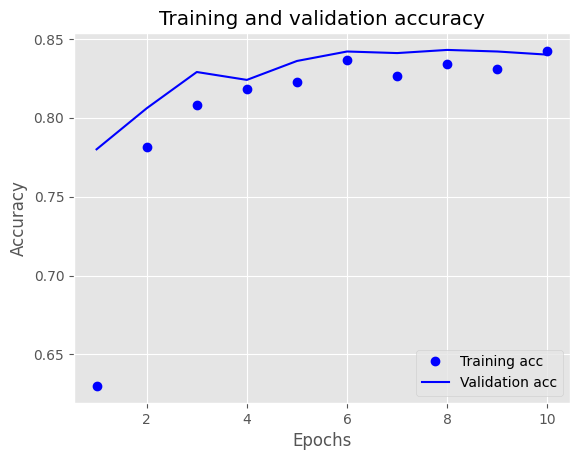

In [ ]:
plt.clf()
acc = history.history['accuracy']
epochs = range(1, len(acc) + 1)
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


## 1.3. Реализация рекуррентной модели.

In [ ]:
x_val = train_data[:1000]
partial_x_train = train_data[1000:]
y_val = one_hot_train_labels[:1000]
partial_y_train = one_hot_train_labels[1000:]
padded_x_val = tf.keras.utils.pad_sequences(x_val, padding="post")
padded_partial_x_train = tf.keras.utils.pad_sequences(partial_x_train, padding="post")
maxLen = padded_x_val[0].shape[0]

numFeatures = 40
numHidden = 45
numClasses = 11
vocabSize = Num_words
model2 = models.Sequential()

model2.add(Embedding(vocabSize, numFeatures,
          input_length=maxLen,
          mask_zero=True)
)

model2.add(Bidirectional(LSTM( numHidden,
            return_sequences=False,
            recurrent_dropout=0.1,
            dropout=0.1))
)

model2.add(layers.Dense(11, activation='softmax'))
model2.summary()

NumEpochs = 4
BatchSize = 512
model2.compile( optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy']
)
history = model2.fit(padded_partial_x_train,
                     partial_y_train,
                    epochs=NumEpochs,
                    batch_size=BatchSize,
                    validation_data=(padded_x_val, y_val)
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
10/10 ━━━━━━━━━━━━━━━━━━━━ 216s 19s/step - accuracy: 0.4777 - loss: 2.2109 - val_accuracy: 0.5150 - val_loss: 1.8583
Epoch 2/4
10/10 ━━━━━━━━━━━━━━━━━━━━ 248s 19s/step - accuracy: 0.5170 - loss: 1.4626 - val_accuracy: 0.5150 - val_loss: 1.2156
Epoch 3/4
10/10 ━━━━━━━━━━━━━━━━━━━━ 191s 19s/step - accuracy: 0.6392 - loss: 1.1009 - val_accuracy: 0.7150 - val_loss: 0.9401
Epoch 4/4
10/10 ━━━━━━━━━━━━━━━━━━━━ 203s 19s/step - accuracy: 0.7346 - loss: 0.8812 - val_accuracy: 0.7540 - val_loss: 0.8012


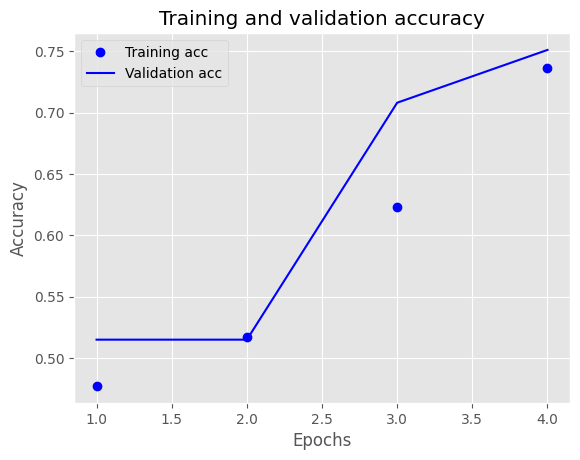

In [ ]:
model2.save('./recur_text_classifier.keras')
plt.clf()
acc = history.history['accuracy']
epochs = range(1, len(acc) + 1)
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Часть 2. Применение LSTM в Python для задач регрессии

In [ ]:
x_train_reshaped = x_train.reshape(x_train.shape[0], 1, x_train.shape[1])
x_val_reshaped = x_val.reshape(x_val.shape[0], 1, x_val.shape[1])
partial_x_train_reshaped = partial_x_train.reshape(partial_x_train.shape[0], 1, partial_x_train.shape[1])

numFeatures = Num_words
numHiddenUnits = 128
numResponses = one_hot_train_labels.shape[1]
numtimesteps = 1

model = Sequential()
model.add(Masking(mask_value=0., input_shape=(numtimesteps, numFeatures)))
model.add(LSTM(numHiddenUnits,
              return_sequences=True,
              recurrent_dropout=0.2,
              dropout=0.2))
model.add(LSTM(numHiddenUnits//2,
          return_sequences=False,
          recurrent_dropout=0.5,
          dropout=0.5))
model.add(Dense(numResponses, activation='softmax'))

maxEpochs = 40
miniBatchSize = 100


model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])


history = model.fit(partial_x_train_reshaped, partial_y_train,
                    epochs=maxEpochs,
                    batch_size=miniBatchSize,
                    validation_data=(x_val_reshaped, y_val),
                    verbose=2, shuffle=False)

Epoch 1/40
52/52 - 9s - 167ms/step - accuracy: 0.6801 - loss: 1.4047 - val_accuracy: 0.7880 - val_loss: 0.7040
Epoch 2/40
52/52 - 1s - 25ms/step - accuracy: 0.8363 - loss: 0.5670 - val_accuracy: 0.8470 - val_loss: 0.5193
Epoch 3/40
52/52 - 1s - 24ms/step - accuracy: 0.8840 - loss: 0.3940 - val_accuracy: 0.8800 - val_loss: 0.4529
Epoch 4/40
52/52 - 1s - 24ms/step - accuracy: 0.9298 - loss: 0.2811 - val_accuracy: 0.9000 - val_loss: 0.4139
Epoch 5/40
52/52 - 2s - 38ms/step - accuracy: 0.9578 - loss: 0.1989 - val_accuracy: 0.9120 - val_loss: 0.3976
Epoch 6/40
52/52 - 1s - 28ms/step - accuracy: 0.9699 - loss: 0.1474 - val_accuracy: 0.9160 - val_loss: 0.4020
Epoch 7/40
52/52 - 1s - 24ms/step - accuracy: 0.9761 - loss: 0.1135 - val_accuracy: 0.9170 - val_loss: 0.4072
Epoch 8/40
52/52 - 1s - 24ms/step - accuracy: 0.9787 - loss: 0.0943 - val_accuracy: 0.9140 - val_loss: 0.4221
Epoch 9/40
52/52 - 1s - 26ms/step - accuracy: 0.9810 - loss: 0.0801 - val_accuracy: 0.9130 - val_loss: 0.4301
Epoch 10/

# Задание № 1: Классификация текстов.
1. Реализовать LSTM модель для классификации 5 типов коротких текстов
на английском. За основу можно взять модель из примера.
2. Добиться чтобы рекуррентная модель стабильно превосходила по качеству базовую модель. Варьировать: количество нейронов, параметры
dropout, количество эпох для обучения.
3. Упорядочить обучающую выборку по длине текстов и найти оптималь
ное разбиение на мини блоки (приводящее к минимальному расширению
нулями в пределах мини выборки). Обязательно проверить, что в модели включено маскирование нулей.
4. Сравнить время обучения модели на упорядоченных данных с мини
мальным числом добавленных нулей и модели с дополнением всех по
следовательностей до одного размера.
5. Как можно улучшить результаты? Попробуйте использовать метод ран
ней остановки и регуляризацию.

In [ ]:
print('Загружаем базу текстов reuters, разбитых на 46 классов в зависимости от их тематики.')
NUM_WORDS=10000 # ограничимся текстами с таком max длиной
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=NUM_WORDS)

def filter_data(data, labels, num_classes=5):
    indices = labels < num_classes
    return data[indices], labels[indices]

x_train_raw, y_train_raw = filter_data(train_data, train_labels)
x_test_raw, y_test_raw = filter_data(test_data, test_labels)
num_classes = 5
y_train_cat = to_categorical(y_train_raw, num_classes)
y_test_cat = to_categorical(y_test_raw, num_classes)
print(f"Обучающая выборка: {x_train_raw.shape}, Тестовая выборка: {x_test_raw.shape}")
val_size = 500
x_val_raw = x_train_raw[:val_size]
y_val_cat = y_train_cat[:val_size]
x_train_partial = x_train_raw[val_size:]
y_train_partial = y_train_cat[val_size:]

x_train_vec = vectorize_sequences(x_train_partial)
x_val_vec = vectorize_sequences(x_val_raw)

Загружаем базу текстов reuters, разбитых на 46 классов в зависимости от их тематики.
Обучающая выборка: (5669,), Тестовая выборка: (1424,)


In [ ]:
baseline_model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(NUM_WORDS,)),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

baseline_model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])
base_history = baseline_model.fit(x_train_vec, y_train_partial, epochs=5, batch_size=512, validation_data=(x_val_vec, y_val_cat), verbose=1)
print(f"Точность базовой модели (val_accuracy): {max(base_history.history['val_accuracy']):.4f}")

Epoch 1/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.6778 - loss: 1.1103 - val_accuracy: 0.8820 - val_loss: 0.4792
Epoch 2/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.8924 - loss: 0.4668 - val_accuracy: 0.9100 - val_loss: 0.3327
Epoch 3/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9276 - loss: 0.3159 - val_accuracy: 0.9200 - val_loss: 0.2896
Epoch 4/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9371 - loss: 0.2526 - val_accuracy: 0.9220 - val_loss: 0.2559
Epoch 5/5
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 98ms/step - accuracy: 0.9564 - loss: 0.1962 - val_accuracy: 0.9280 - val_loss: 0.2463
Точность базовой модели (val_accuracy): 0.9280


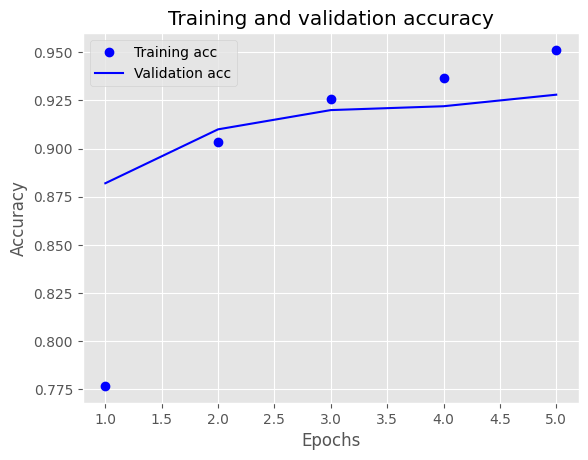

In [ ]:
plt.clf()
acc = base_history.history['accuracy']
epochs = range(1, len(acc) + 1)
val_acc = base_history.history['val_accuracy']
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
print("\n--- Подготовка данных для сравнения времени обучения ---")

sorted_data = sorted(zip(x_train_partial, y_train_partial), key=lambda pair: len(pair[0]))
x_train_sorted = np.array([x for x, y in sorted_data], dtype=object)
y_train_sorted = np.array([y for x, y in sorted_data])

def smart_batch_generator(x_data, y_data, batch_size):
    num_samples = len(x_data)
    while True:
        for offset in range(0, num_samples, batch_size):
            batch_x = x_data[offset:offset+batch_size]
            batch_y = y_data[offset:offset+batch_size]
            max_len_in_batch = max(len(s) for s in batch_x)
            batch_x_padded = pad_sequences(batch_x, maxlen=max_len_in_batch, padding='post')

            yield batch_x_padded, batch_y


global_maxlen = max(len(s) for s in np.concatenate((x_train_partial, x_val_raw)))
print(f"Global Max Length: {global_maxlen}")

x_train_padded_static = pad_sequences(x_train_partial, maxlen=global_maxlen, padding='post')
x_val_padded_static = pad_sequences(x_val_raw, maxlen=global_maxlen, padding='post')


--- Подготовка данных для сравнения времени обучения ---
Global Max Length: 2376


In [ ]:
def build_lstm_model():
    model = models.Sequential()

    model.add(layers.Embedding(NUM_WORDS, 64, mask_zero=True))
    model.add(layers.Bidirectional(layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0)))

    #model.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

BATCH_SIZE = 64
EPOCHS = 3

print("\nЗапуск обучения на стандартном пэддинге...")
model_static = build_lstm_model()
start_time = time.time()
model_static.fit(x_train_padded_static, y_train_partial,
                 epochs=EPOCHS, batch_size=BATCH_SIZE,
                 validation_data=(x_val_padded_static, y_val_cat), verbose=0)
time_static = time.time() - start_time
print(f"Время обучения (Стандартный пэддинг): {time_static:.2f} сек.")


print("Запуск обучения на сортированных данных (Smart Batching)...")
model_smart = build_lstm_model()
def generator_wrapper():
    return smart_batch_generator(x_train_sorted, y_train_sorted, BATCH_SIZE)

output_signature = (
    tf.TensorSpec(shape=(None, None), dtype=tf.int32),
    tf.TensorSpec(shape=(None, num_classes), dtype=tf.float32)
)
train_dataset = tf.data.Dataset.from_generator(
    generator_wrapper,
    output_signature=output_signature
)
steps_per_epoch = len(x_train_sorted) // BATCH_SIZE

start_time = time.time()
model_smart.fit(train_dataset,
                steps_per_epoch=steps_per_epoch,
                epochs=EPOCHS,
                validation_data=(x_val_padded_static, y_val_cat),
                verbose=0)

time_smart = time.time() - start_time
print(f"Время обучения (Сортировка + Smart Batching): {time_smart:.2f} сек.")
print(f"Ускорение: {time_static / time_smart:.2f}x")


Запуск обучения на стандартном пэддинге...
Время обучения (Стандартный пэддинг): 1502.60 сек.
Запуск обучения на сортированных данных (Smart Batching)...
Время обучения (Сортировка + Smart Batching): 114.41 сек.
Ускорение: 13.13x


In [ ]:
def build_lstm_model():
    model = models.Sequential()

    model.add(layers.Embedding(NUM_WORDS, 64, mask_zero=True))
    model.add(layers.Bidirectional(layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0)))

    model.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

early_stop = callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)

final_model = build_lstm_model()
final_history = final_model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    epochs=20,
    validation_data=(x_val_padded_static, y_val_cat),
    callbacks=[early_stop],
    verbose=1
)

final_acc = max(history.history['val_accuracy'])
print(f"\nФинальная точность LSTM модели: {final_acc:.4f}")

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.7707 - loss: 1.1150 - val_accuracy: 0.8480 - val_loss: 0.5300
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9101 - loss: 0.3485 - val_accuracy: 0.9120 - val_loss: 0.3345
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9452 - loss: 0.2625 - val_accuracy: 0.9100 - val_loss: 0.3181
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9481 - loss: 0.2293 - val_accuracy: 0.9320 - val_loss: 0.2927
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9542 - loss: 0.2017 - val_accuracy: 0.8960 - val_loss: 0.3947
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9604 - loss: 0.1773 - val_accuracy: 0.9160 - val_loss: 0.3483
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9642 - loss: 0.1541 - val_accuracy: 0.9200 - val_loss: 0.3331

Финальная точность LSTM модели: 0.9360


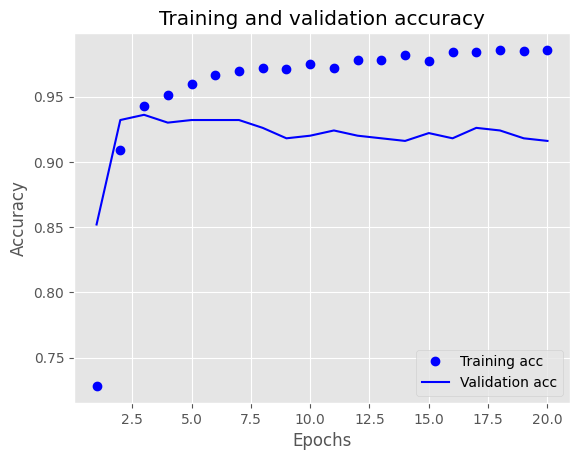

In [ ]:
final_model.save('./recur_text_classifier_final_.keras')
plt.clf()
acc = history.history['accuracy']
epochs = range(1, len(acc) + 1)
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Задание № 2: Предсказание времени отказа для ракетных двигателей.
1. Скачать данные с сайта НАСА https://ti.arc.nasa.gov/c/6/
2. В первой колонке указаны идентефикаторы двигателей. Нужно объеди
нить все данные с одинаковым идентификатором в отдельные последо
вательности.
3. Использовать данные из колонок 3–26 в качестве данных для входов.
4. Для каждого двигателя посчитать RUL = max значения его второй колонки (сколько тактов проработал двигатель).
5. В качестве эталонных данных для регрессии использовать прогноз по
оставшимся рабочим циклам двигателя. Получить его как разность RUL
и значений во второй колонке. Нейронная сеть в ответ на последова
тельность данных телеметрии должна выдать одно значение — сколько
двигателю осталось проработать после последней записи.
6. Удалить из выборки константные данные. Нормализовать данные, и
опционально обрезать эталонные значения на уровне 150 тактов двига
телей. То есть оставить последние 150 записей для всех проработавших
дольше двигателей.
7. Подготовить обучающую выборку, выделяя из полных данных телеметрии подпоследовательности длины от 50 до 150.
8. Упорядочить обучающую выборку по длине последовательностей и найти оптимальное разбиение на мини блоки.
9. Реализовать регрессионную модель, предусмотрев маскирование нуле
вых данных. За основу взять рассмотренный пример, дополнив его но
выми слоями при желании, а также подбирая оптимальные настройки
dropout.
10. Обучить сеть и проверить качество предсказаний. Сравнить по времени
с обучением без упорядочивания по длине.
11. Как можно улучшить результаты? Попробуйте использовать метод ранней остановки и batch normalization

In [1]:
import os
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers, regularizers, optimizers, callbacks
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import MinMaxScaler
import zipfile
import pandas as pd
import numpy as np
import io
import requests

plt.style.use('ggplot')
import warnings
warnings.filterwarnings('ignore')

In [ ]:
FILE_PATH = '/content/drive/MyDrive/test_FD001.txt'
if not os.path.exists(FILE_PATH):
    print("\nошибка: Файл не найден по этому пути")
else:
    print("Файл найден")
    columns = ['id', 'cycle', 'setting1', 'setting2', 'setting3', 's1', 's2', 's3',
               's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14',
               's15', 's16', 's17', 's18', 's19', 's20', 's21']

    train_df = pd.read_csv(FILE_PATH, sep='\s+', header=None, names=columns)
    print("Размер загруженных данных:", train_df.shape)
    print("\n--- Расчет RUL и подготовка признаков ---")

    max_cycles = train_df.groupby('id')['cycle'].max().reset_index()
    max_cycles.columns = ['id', 'max_cycle']
    train_df = train_df.merge(max_cycles, on='id', how='left')
    train_df['RUL'] = train_df['max_cycle'] - train_df['cycle']

    cols_to_drop = ['id', 'cycle', 'max_cycle']
    features = [c for c in train_df.columns if c not in cols_to_drop and c != 'RUL']
    print(f"Используемые признаки ({len(features)}): {features}")

    scaler = MinMaxScaler(feature_range=(0, 1))
    train_df[features] = scaler.fit_transform(train_df[features])

    print("Данные успешно загружены и предобработаны.")
    print(train_df.head())

Файл найден
Размер загруженных данных: (13096, 26)

--- Расчет RUL и подготовка признаков ---
Используемые признаки (24): ['setting1', 'setting2', 'setting3', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']
Данные успешно загружены и предобработаны.
   id  cycle  setting1  setting2  setting3   s1        s2        s3        s4  \
0   1      1   0.65625  0.692308       0.0  0.0  0.596215  0.421968  0.282214   
1   1      2   0.34375  0.230769       0.0  0.0  0.182965  0.504025  0.225240   
2   1      3   0.53125  0.538462       0.0  0.0  0.419558  0.464814  0.346130   
3   1      4   0.77500  0.461538       0.0  0.0  0.413249  0.391587  0.449867   
4   1      5   0.60000  0.461538       0.0  0.0  0.435331  0.471306  0.357974   

    s5  ...       s14       s15  s16    s17  s18  s19       s20       s21  \
0  0.0  ...  0.152259  0.347076  0.0  0.375  0.0  0.0  0.500000  0.620099   
1  0.0  ...  0.2779

In [ ]:
def gen_sequence(id_df, seq_cols, min_len=50, max_clip=150):
    data_array = id_df[seq_cols].values
    num_elements = data_array.shape[0]

    if num_elements > max_clip:
        data_array = data_array[-max_clip:]
    elif num_elements < min_len:
         pass

    return data_array

seq_gen = []
rul_target = []
for engine_id in train_df['id'].unique():
    current_engine = train_df[train_df['id'] == engine_id]
    seq = gen_sequence(current_engine, features)
    last_cycle_idx = current_engine.index[-1]
    last_rul = train_df.iloc[last_cycle_idx]['RUL']
    seq_gen.append(seq)
    rul_target.append(last_rul)

X_list = []
Y_list = []
for engine_id in train_df['id'].unique():
    eng_data = train_df[train_df['id'] == engine_id]
    for stop_point in range(50, len(eng_data), 10):
        start_point = max(0, stop_point - 50)
        sub_seq = eng_data[features].iloc[start_point:stop_point].values
        target = eng_data['RUL'].iloc[stop_point-1]

        X_list.append(sub_seq)
        Y_list.append(target)

X_data = np.array(X_list, dtype=object)
Y_data = np.array(Y_list)

print(f"Сформировано сэмплов: {len(X_data)}")
print(f"Пример размерности одного сэмпла: {X_data[0].shape}")
print(f"Пример RUL: {Y_data[:5]}")

val_split = int(len(X_data) * 0.2)
X_train = X_data[:-val_split]
Y_train = Y_data[:-val_split]
X_val = X_data[-val_split:]
Y_val = Y_data[-val_split:]

Сформировано сэмплов: 862
Пример размерности одного сэмпла: (50, 24)
Пример RUL: [76 66 56 46 36]


In [ ]:
sorted_indices = np.argsort([len(x) for x in X_train])
X_train_sorted = X_train[sorted_indices]
Y_train_sorted = Y_train[sorted_indices]

global_maxlen = 150
X_val_padded = pad_sequences(X_val, maxlen=global_maxlen, padding='post', dtype='float32', value=-1.0) # -1 для маскирования

def smart_batch_generator(X, Y, batch_size):
    num_samples = len(X)
    while True:
        for offset in range(0, num_samples, batch_size):
            batch_x_raw = X[offset:offset+batch_size]
            batch_y = Y[offset:offset+batch_size]

            max_len = max(len(x) for x in batch_x_raw)

            batch_x_padded = pad_sequences(batch_x_raw, maxlen=max_len, padding='post', dtype='float32', value=-1.0)

            yield batch_x_padded, batch_y

In [ ]:
def create_dataset(X, Y, batch_size):
    def gen():
        return smart_batch_generator(X, Y, batch_size)

    output_signature = (
        tf.TensorSpec(shape=(None, None, len(features)), dtype=tf.float32),
        tf.TensorSpec(shape=(None,), dtype=tf.float32)
    )
    dataset = tf.data.Dataset.from_generator(gen, output_signature=output_signature)
    return dataset

In [ ]:
def build_regression_model(input_dim):
    model = models.Sequential()

    model.add(layers.Masking(mask_value=-1.0, input_shape=(None, input_dim)))

    model.add(layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.01)) # recurrent_dropout=0 для GPU

    model.add(layers.BatchNormalization())

    model.add(layers.LSTM(64, return_sequences=False, dropout=0.2))
    model.add(layers.BatchNormalization())

    model.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(1, activation='linear'))

    model.compile(loss='mse', optimizer='adam', metrics=['mae'])
    return model

BATCH_SIZE = 64
num_features = len(features)

print("\n--- Запуск обучения: стандартный паддинг ---")
X_train_static = pad_sequences(X_train, maxlen=global_maxlen, padding='post', dtype='float32', value=-1.0)

model_static = build_regression_model(num_features)
start_t = time.time()
hist_static = model_static.fit(
    X_train_static, Y_train,
    epochs=25,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_padded, Y_val),
    verbose=1
)
time_static = time.time() - start_t
print(f"Время: {time_static:.2f} сек. MAE: {hist_static.history['val_mae'][-1]:.2f}")


--- Запуск обучения: стандартный паддинг ---
Epoch 1/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 458ms/step - loss: 5408.7871 - mae: 59.1616 - val_loss: 5652.8726 - val_mae: 60.1564
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 362ms/step - loss: 4855.6807 - mae: 56.0823 - val_loss: 5612.9707 - val_mae: 59.8166
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 671ms/step - loss: 4758.4033 - mae: 55.0091 - val_loss: 5574.1021 - val_mae: 59.4392
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 366ms/step - loss: 4235.6162 - mae: 51.7027 - val_loss: 5434.6772 - val_mae: 58.2381
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 372ms/step - loss: 4176.7222 - mae: 49.4410 - val_loss: 4773.7993 - val_mae: 52.5891
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 591ms/step - loss: 3856.3872 - mae: 47.5299 - val_loss: 5208.0713 - val_mae: 56.2364
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 366ms/step - loss: 3480.5847 - mae: 44.2985 - val_loss: 3088.2544 - val_mae: 40.7510
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 605ms/step - loss: 2587.6262 -

KeyboardInterrupt: 

In [ ]:
print("\n--- Запуск обучения: сортировка + Smart Batching ---")
model_smart = build_regression_model(num_features)
train_dataset = create_dataset(X_train_sorted, Y_train_sorted, BATCH_SIZE)
steps = len(X_train_sorted) // BATCH_SIZE

early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

start_t = time.time()
hist_smart = model_smart.fit(
    train_dataset,
    steps_per_epoch=steps,
    epochs=10,
    validation_data=(X_val_padded, Y_val), # Валидацию оставляем падденной статически
    callbacks=[early_stop],
    verbose=1
)
time_smart = time.time() - start_t

print(f"\nВремя: {time_smart:.2f} сек.")
print(f"Ускорение: {time_static / time_smart:.2f}x")



--- Запуск обучения: сортировка + Smart Batching ---
Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 531ms/step - loss: 5306.2158 - mae: 59.1316 - val_loss: 5629.6133 - val_mae: 59.9659
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - loss: 4632.3569 - mae: 54.9359 - val_loss: 5573.5854 - val_mae: 59.5017
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 242ms/step - loss: 4349.2783 - mae: 52.3525 - val_loss: 5510.3501 - val_mae: 58.9373
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 238ms/step - loss: 4390.0469 - mae: 52.1975 - val_loss: 5333.6499 - val_mae: 57.4771
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 242ms/step - loss: 3582.8250 - mae: 47.2353 - val_loss: 5269.5337 - val_mae: 56.7830
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 361ms/step - loss: 4535.7793 - mae: 51.2280 - val_loss: 4914.5449 - val_mae: 53.8778
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 385ms/step - loss: 3928.5696 - mae: 45.9994 - val_loss: 4626.3291 - val_mae: 51.5218
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step - loss: 334

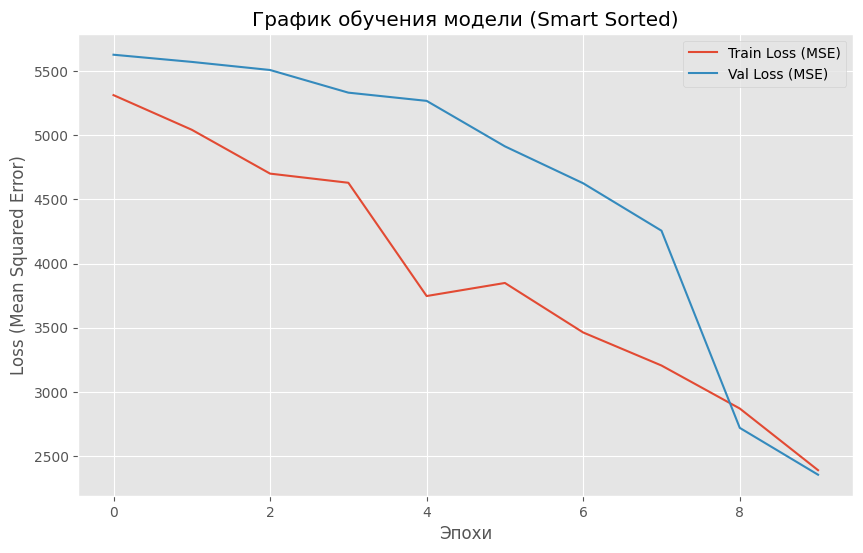


--- Пример предсказания ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 819ms/step
RUL: 42.25


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(hist_smart.history['loss'], label='Train Loss (MSE)')
plt.plot(hist_smart.history['val_loss'], label='Val Loss (MSE)')
plt.title('График обучения модели (Smart Sorted)')
plt.xlabel('Эпохи')
plt.ylabel('Loss (Mean Squared Error)')
plt.legend()
plt.show()

print("\n--- Пример предсказания ---")
sample_idx = 0
sample_input = X_val_padded[sample_idx:sample_idx+1]
true_rul = Y_val[sample_idx]
pred_rul = model_smart.predict(sample_input)[0][0]
print(f"RUL: {pred_rul:.2f}")